# ENTSO-E 2019–2023 Data Analysis

**Purpose:** Understand the ENTSO-E day-ahead price data before running any models on it.  
This notebook mirrors the structure of `draft_data.ipynb` (benchmark 2015–2018) for the new period.

**Why this comes first:** The AR-LEAR retrain on FR 2022–2023 produced MAE = 24 EUR/MWh  
(vs 3.98 for the benchmark). Before interpreting that number, we need to know what prices  
actually looked like — regime breaks, tail events, and whether an AR model with no exogenous  
features can reasonably be expected to track this period.

**Markets:** FR, BE, NP, DE (no PJM — not available for 2019–2023).  
**Data source:** ENTSO-E Transparency Platform day-ahead prices.

**Structure:**
- Section 0: Setup & data loading
- Section 1: Price statistics by market and year
- Section 2: Time series & regime identification
- Section 3: Price distributions
- Section 4: Seasonal structure
- Section 5: Tail concentration
- Section 6: Cross-market dependence
- Section 7: Comparison with benchmark period (2015–2018)

---
## Section 0 — Setup & Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, skew

plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})

ENTSO_PATH = 'data/raw/entso_e/'
MARKETS = ['FR', 'BE', 'NP', 'DE']

def load_entso_price(market):
    """Load ENTSO-E day-ahead price CSV → naive UTC hourly index, single 'Price' column."""
    path = ENTSO_PATH + f'{market}_dayahead_2019_2023.csv'
    df = pd.read_csv(path, index_col=0)
    df.columns = ['Price']
    df.index = pd.to_datetime(df.index, utc=True).tz_localize(None)
    df = df.asfreq('h')
    df['Price'] = df['Price'].ffill(limit=1)  # 1 missing hour per year (Dec 31 00:00 CET)
    # Trim to complete UTC days (LEAR requires hour-0 start)
    first_midnight = df.index[df.index.hour == 0][0]
    last_h23 = df.index[df.index.hour == 23][-1]
    df = df.loc[first_midnight:last_h23]
    return df

all_data = {}
for mkt in MARKETS:
    all_data[mkt] = load_entso_price(mkt)
    df = all_data[mkt]
    print(f'{mkt}: {len(df):,} rows  {df.index[0].date()} -> {df.index[-1].date()}  '
          f'NaN={df["Price"].isna().sum()}  neg={int((df["Price"]<0).sum())}')

FR: 43,800 rows  2019-01-01 -> 2023-12-30  NaN=0  neg=344
BE: 43,800 rows  2019-01-01 -> 2023-12-30  NaN=0  neg=696
NP: 43,800 rows  2019-01-01 -> 2023-12-30  NaN=0  neg=391
DE: 43,656 rows  2019-01-07 -> 2023-12-30  NaN=0  neg=994


---
## Section 1 — Price Statistics by Market and Year

**What we are testing:** How different are the price regimes across years?  
2019 = normal, 2020 = COVID, 2021 = recovery, 2022 = energy crisis, 2023 = post-crisis.  
If price levels and volatility change by an order of magnitude between years,  
a rolling-window model trained on one regime will struggle on the next.

**What the result would mean:**  
- If 2022 is 5–10× the other years → AR-LEAR MAE of 24 is explained by price level, not model failure  
- If kurtosis spikes in 2022 → the tail is fatter, which is exactly the regime where the thesis predicts larger divergence  
- If 2023 normalises → we might want to test 2023 separately from 2022

In [2]:
years = ['2019', '2020', '2021', '2022', '2023']

print(f"{'Market':6} {'Year':5} {'Mean':>8} {'Std':>8} {'Min':>8} {'Max':>8} "
      f"{'Skew':>7} {'Kurt':>7} {'Neg%':>6}")
print('-' * 75)

for mkt in MARKETS:
    for yr in years:
        p = all_data[mkt].loc[yr, 'Price'].dropna()
        if len(p) == 0:
            continue
        print(f"{mkt:6} {yr:5} {p.mean():8.1f} {p.std():8.1f} {p.min():8.0f} {p.max():8.0f} "
              f"{skew(p):7.1f} {kurtosis(p, fisher=True):7.1f} "
              f"{100*(p<0).mean():5.1f}%")
    print()

Market Year      Mean      Std      Min      Max    Skew    Kurt   Neg%
---------------------------------------------------------------------------
FR     2019      39.4     14.0      -25      121     0.3     1.4   0.3%
FR     2020      32.2     16.1      -76      200     0.6     4.6   1.2%
FR     2021     109.2     84.3      -66      620     1.7     3.1   0.7%
FR     2022     275.9    145.8       -1     2988     2.2    23.1   0.0%
FR     2023      97.1     45.4     -135      276    -0.1     0.5   1.7%

BE     2019      39.3     18.0     -500      121    -9.1   231.9   0.8%
BE     2020      31.9     16.5     -115      200     0.1     7.7   1.5%
BE     2021     104.1     79.4      -70      620     1.6     3.3   1.8%
BE     2022     244.5    134.7     -100      871     0.8     1.1   1.3%
BE     2023      97.5     45.7     -120      330    -0.1     0.9   2.5%

NP     2019      39.3      8.3        6      109     1.3     6.5   0.0%
NP     2020       9.3      8.3       -2      100     1.9  

---
## Section 2 — Time Series & Regime Identification

**What we are looking for:** Visual confirmation of the regime breaks.  
A rolling 7-day mean shows the structural shifts; the raw hourly series shows the spikes.

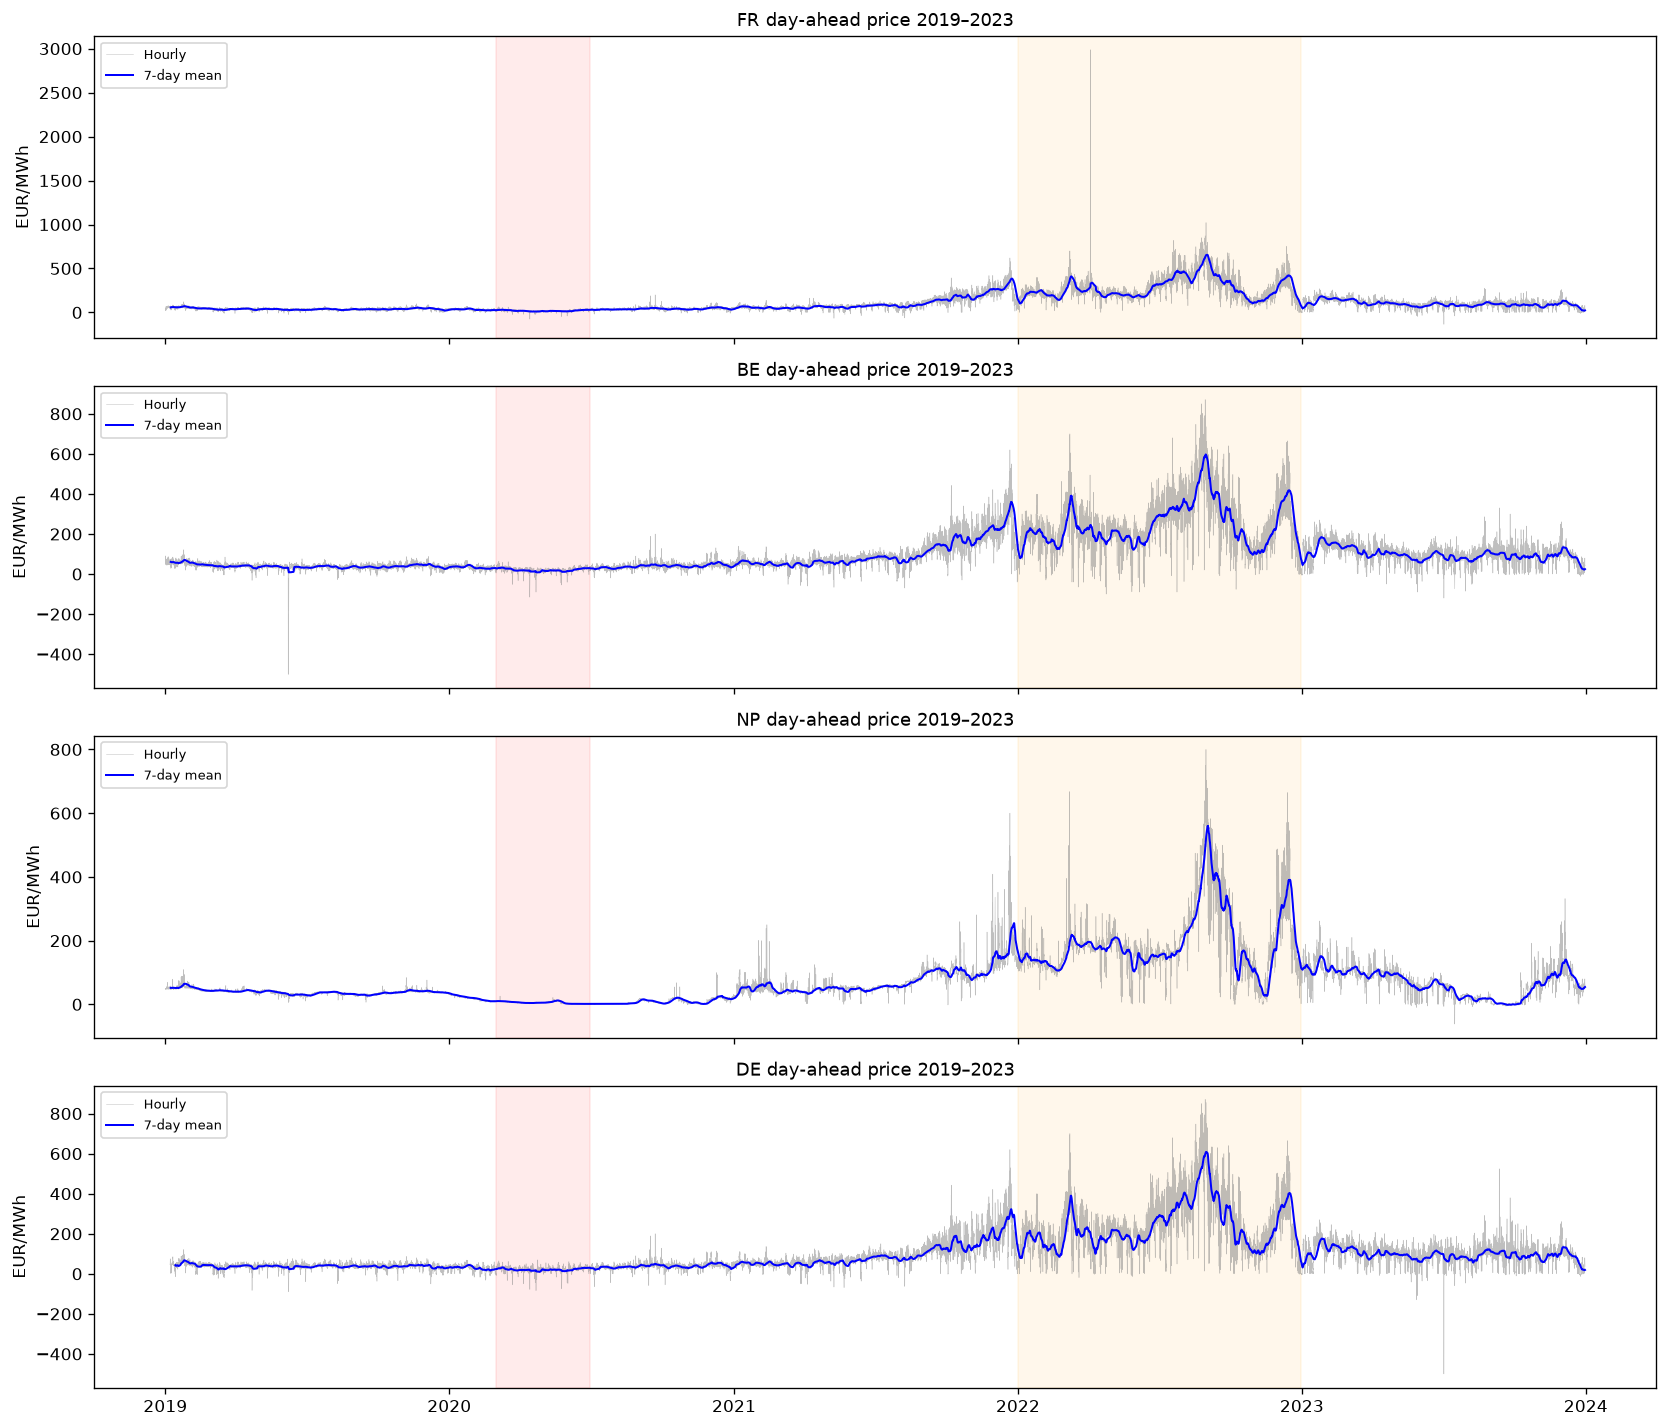

Saved: figs/entso_timeseries.png


In [3]:
fig, axes = plt.subplots(len(MARKETS), 1, figsize=(14, 3*len(MARKETS)), sharex=True)

for ax, mkt in zip(axes, MARKETS):
    p = all_data[mkt]['Price']
    ax.plot(p.index, p.values, linewidth=0.3, alpha=0.5, color='grey', label='Hourly')
    roll = p.rolling(7*24).mean()
    ax.plot(roll.index, roll.values, linewidth=1.2, color='blue', label='7-day mean')
    ax.set_ylabel('EUR/MWh')
    ax.set_title(f'{mkt} day-ahead price 2019–2023', fontsize=11)
    ax.legend(loc='upper left', fontsize=8)
    # Shade regimes
    ax.axvspan('2020-03-01', '2020-06-30', alpha=0.08, color='red', label='COVID')
    ax.axvspan('2022-01-01', '2022-12-31', alpha=0.08, color='orange', label='Energy crisis')

plt.tight_layout()
plt.savefig('figs/entso_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figs/entso_timeseries.png')

---
## Section 3 — Price Distributions

**What we are testing:** How do the distributions compare to the benchmark period?  
The benchmark had FR kurtosis 522 (nuclear spikes). Does 2022 have even heavier tails?

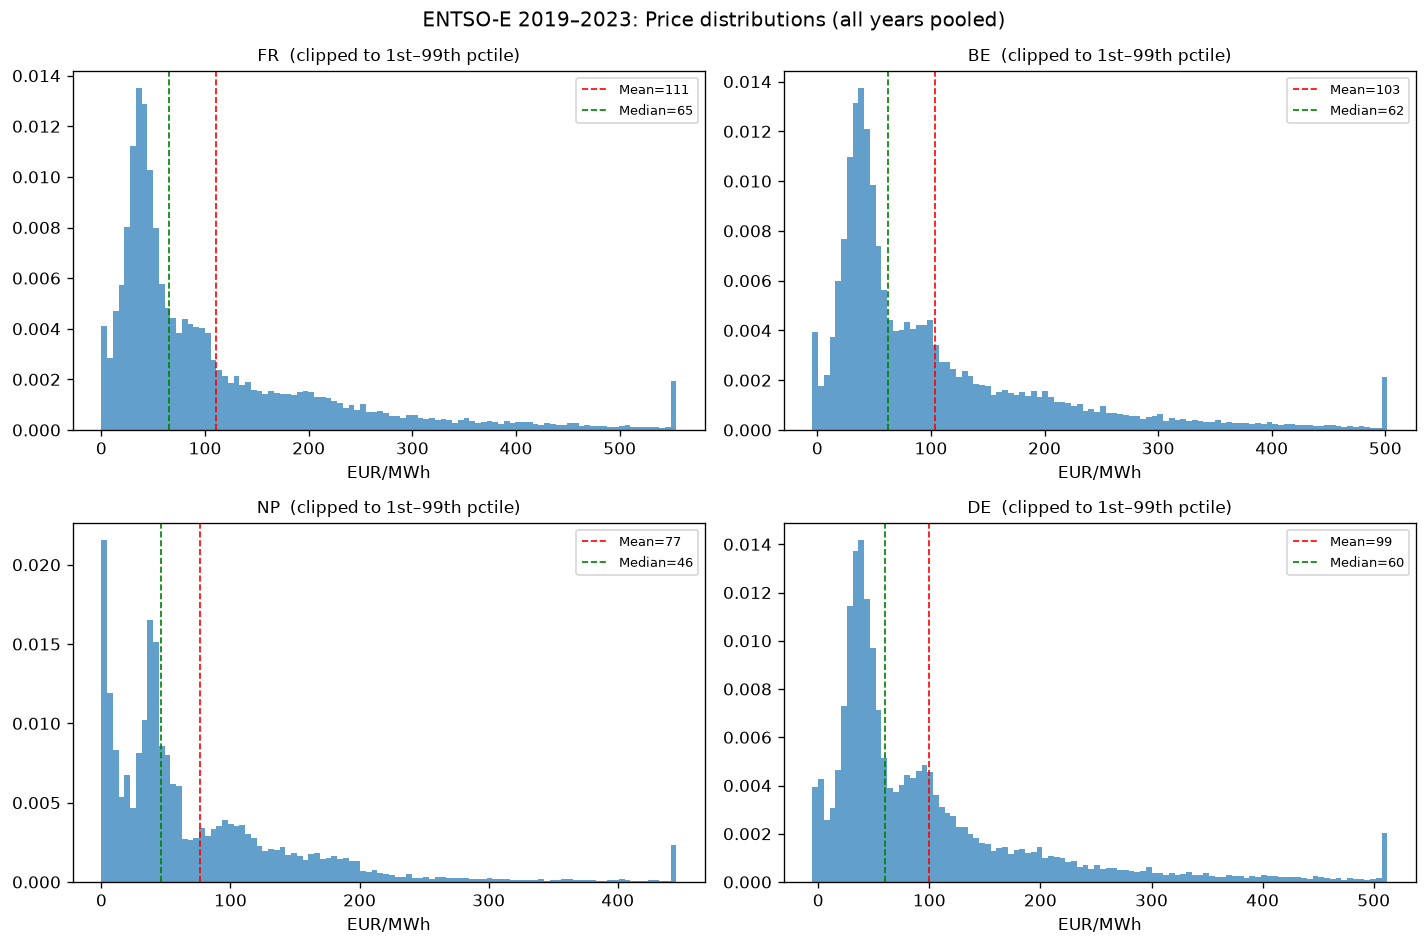

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, mkt in zip(axes.flat, MARKETS):
    p = all_data[mkt]['Price'].dropna()
    # Clip for visualisation but report unclipped stats
    lo, hi = p.quantile(0.01), p.quantile(0.99)
    ax.hist(p.clip(lo, hi), bins=100, density=True, alpha=0.7, edgecolor='none')
    ax.axvline(p.mean(), color='red', linestyle='--', linewidth=1, label=f'Mean={p.mean():.0f}')
    ax.axvline(p.median(), color='green', linestyle='--', linewidth=1, label=f'Median={p.median():.0f}')
    ax.set_title(f'{mkt}  (clipped to 1st–99th pctile)', fontsize=10)
    ax.set_xlabel('EUR/MWh')
    ax.legend(fontsize=8)

plt.suptitle('ENTSO-E 2019–2023: Price distributions (all years pooled)', fontsize=12)
plt.tight_layout()
plt.savefig('figs/entso_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 4 — Seasonal Structure

**What we are looking for:** Does the intraday/weekly pattern hold during the crisis,  
or does the crisis flatten or distort the usual shape?

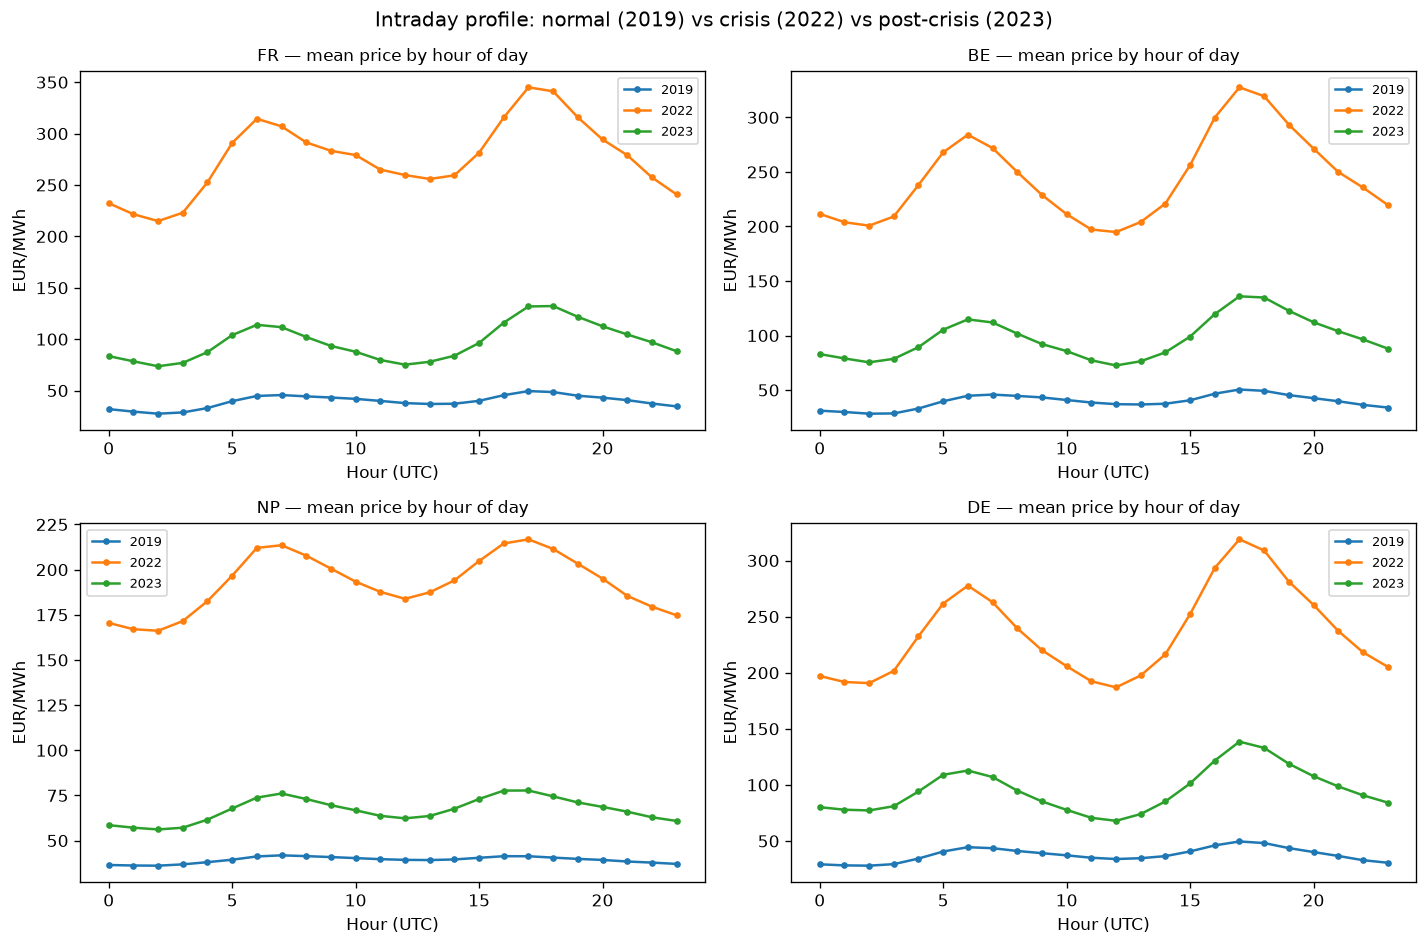

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, mkt in zip(axes.flat, MARKETS):
    df = all_data[mkt].copy()
    df['hour'] = df.index.hour
    df['year'] = df.index.year
    for yr in [2019, 2022, 2023]:
        hourly = df[df['year'] == yr].groupby('hour')['Price'].mean()
        ax.plot(hourly.index, hourly.values, marker='o', markersize=3, label=str(yr))
    ax.set_title(f'{mkt} — mean price by hour of day', fontsize=10)
    ax.set_xlabel('Hour (UTC)')
    ax.set_ylabel('EUR/MWh')
    ax.legend(fontsize=8)

plt.suptitle('Intraday profile: normal (2019) vs crisis (2022) vs post-crisis (2023)', fontsize=12)
plt.tight_layout()
plt.savefig('figs/entso_seasonal.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 5 — Tail Concentration

**What we are testing:** What share of total electricity cost falls in the worst 5% of hours?  
If the tail is heavier in 2022 than in the benchmark, the CVaR-based decision becomes more  
important — and the accuracy/value gap should widen.

In [6]:
print(f"{'Market':6} {'Year':5} {'Total cost':>12} {'Top 5% cost':>12} {'Share':>7} {'Uniform':>8}")
print('-' * 60)

for mkt in MARKETS:
    for yr in years:
        p = all_data[mkt].loc[yr, 'Price'].dropna()
        if len(p) == 0:
            continue
        p_pos = p[p > 0]  # only positive prices contribute to cost
        total = p_pos.sum()
        threshold = p_pos.quantile(0.95)
        tail_cost = p_pos[p_pos >= threshold].sum()
        share = tail_cost / total * 100 if total > 0 else 0
        uniform_share = 5.0  # uniform benchmark
        print(f"{mkt:6} {yr:5} {total:12,.0f} {tail_cost:12,.0f} {share:6.1f}% {uniform_share:7.1f}%")
    print()

Market Year    Total cost  Top 5% cost   Share  Uniform
------------------------------------------------------------
FR     2019       345,732       31,739    9.2%     5.0%
FR     2020       284,022       30,082   10.6%     5.0%
FR     2021       957,271      154,807   16.2%     5.0%
FR     2022     2,416,612      286,676   11.9%     5.0%
FR     2023       849,281       83,192    9.8%     5.0%

BE     2019       348,406       31,489    9.0%     5.0%
BE     2020       282,603       30,237   10.7%     5.0%
BE     2021       915,144      143,896   15.7%     5.0%
BE     2022     2,145,114      254,101   11.8%     5.0%
BE     2023       854,188       83,251    9.7%     5.0%

NP     2019       344,142       26,827    7.8%     5.0%
NP     2020        81,588       13,062   16.0%     5.0%
NP     2021       654,360       96,754   14.8%     5.0%
NP     2022     1,686,334      225,395   13.4%     5.0%
NP     2023       586,192       68,577   11.7%     5.0%

DE     2019       327,772       28,503  

---
## Section 6 — Cross-Market Dependence

**What we are testing:** Are FR and BE still highly correlated (as in the benchmark: r=0.79)?  
During a common shock (gas crisis), correlations may increase — which would further reduce  
the effective number of independent markets.

In [7]:
# Build a price matrix on the common date range
price_mat = pd.DataFrame({mkt: all_data[mkt]['Price'] for mkt in MARKETS})
price_mat = price_mat.dropna()

print('Price correlation matrix (full period):')
print(price_mat.corr().round(3))
print()

# By year
for yr in years:
    sub = price_mat.loc[yr]
    if len(sub) < 100:
        continue
    print(f'{yr}: FR-BE r={sub["FR"].corr(sub["BE"]):.3f}  '
          f'FR-DE r={sub["FR"].corr(sub["DE"]):.3f}  '
          f'NP-FR r={sub["NP"].corr(sub["FR"]):.3f}')

Price correlation matrix (full period):
       FR     BE     NP     DE
FR  1.000  0.953  0.870  0.934
BE  0.953  1.000  0.879  0.971
NP  0.870  0.879  1.000  0.877
DE  0.934  0.971  0.877  1.000

2019: FR-BE r=0.771  FR-DE r=0.789  NP-FR r=0.678
2020: FR-BE r=0.942  FR-DE r=0.881  NP-FR r=0.377
2021: FR-BE r=0.969  FR-DE r=0.906  NP-FR r=0.826
2022: FR-BE r=0.871  FR-DE r=0.859  NP-FR r=0.727
2023: FR-BE r=0.974  FR-DE r=0.883  NP-FR r=0.580


---
## Section 7 — Comparison with Benchmark Period

**What we are testing:** How does 2022–2023 (the intended test period for AR-LEAR)  
compare to 2015–2018 (the benchmark period)?  
This determines whether the two periods are comparable at all,  
or whether the new period is a fundamentally different problem.

In [8]:
# Load benchmark data for the markets we have in both periods
ZENODO_PATH = 'data/raw/epftoolbox/'
benchmark_stats = {}

for mkt in MARKETS:
    df_z = pd.read_csv(ZENODO_PATH + mkt + '.csv', index_col=0, parse_dates=True)
    # Zenodo columns: Price is always the first data column
    price_col = df_z.columns[0]
    p_bench = df_z[price_col].dropna()
    p_new   = all_data[mkt].loc['2022':'2023', 'Price'].dropna()
    
    print(f'{mkt}:')
    print(f'  Benchmark ({p_bench.index[0].year}-{p_bench.index[-1].year}): '
          f'mean={p_bench.mean():.1f}  std={p_bench.std():.1f}  '
          f'kurt={kurtosis(p_bench, fisher=True):.1f}  '
          f'neg={100*(p_bench<0).mean():.1f}%')
    print(f'  New (2022-2023):       '
          f'mean={p_new.mean():.1f}  std={p_new.std():.1f}  '
          f'kurt={kurtosis(p_new, fisher=True):.1f}  '
          f'neg={100*(p_new<0).mean():.1f}%')
    ratio = p_new.mean() / p_bench.mean() if p_bench.mean() > 0 else float('nan')
    print(f'  Mean ratio: {ratio:.1f}x')
    print()

FR:
  Benchmark (2011-2016): mean=41.5  std=23.1  kurt=1702.6  neg=0.1%
  New (2022-2023):       mean=186.6  std=140.2  kurt=17.0  neg=0.9%
  Mean ratio: 4.5x

BE:
  Benchmark (2011-2016): mean=44.3  std=23.1  kurt=5168.8  neg=0.0%
  New (2022-2023):       mean=171.1  std=124.6  kurt=2.5  neg=1.9%
  Mean ratio: 3.9x

NP:
  Benchmark (2013-2018): mean=31.4  std=10.6  kurt=7.0  neg=0.0%
  New (2022-2023):       mean=129.8  std=104.7  kurt=4.2  neg=2.2%
  Mean ratio: 4.1x

DE:
  Benchmark (2012-2017): mean=34.7  std=15.9  kurt=16.3  neg=1.0%
  New (2022-2023):       mean=165.5  std=127.4  kurt=2.9  neg=2.1%
  Mean ratio: 4.8x

